# 07 - Évaluer le modèle sur 2024 et conclure

Le notebook 06 a comparé une référence constante et une régression logistique sur 2023.
Il a retenu une configuration avant de calculer les performances de 2024. Nous reprenons
cette configuration pour répondre à la dernière question de modélisation :

**L'information prédictive observée en validation se maintient-elle sur les usagers enregistrés en 2024 ?**

L'unité reste l'usager impliqué dans un accident corporel enregistré en France métropolitaine,
Corse comprise. La cible vaut 1 pour un décès ou une hospitalisation et 0 pour un usager
indemne ou blessé léger. Les gravités inconnues sont comptées puis exclues de l'évaluation.
Cette cible ne constitue pas une définition médicale uniforme des blessures graves.

Nous évaluons une étude rétrospective, sans revendiquer de prédiction avant un trajet,
de prévision de survenue d'accident ou d'aide aux secours en temps réel.
2024 a déjà été examinée dans les audits de structure ; ses scores n'ont pas servi au réglage.
Une fois les performances consultées, cette année ne peut plus servir de nouveau test
indépendant pour sélectionner d'autres variantes. Relancer ce notebook vérifie la reproduction
de la même évaluation, sans créer un nouveau jeu de test.

Les commentaires chiffrés correspondent à la revue du 17 octobre 2026. Les empreintes et
versions sont enregistrées ; ces commentaires sont à relire si les entrées changent.


## 1. Ce qui est déjà décidé et ce que nous allons vérifier

Le test reprend les onze variables, les huit tranches d'âge, la modalité « Non renseigné »,
l'encodage et le C retenu dans `reports/tables/06_modeling/06_configuration_retenue.json`. La régression est reconstruite
sur **2019-2022 uniquement**. Ajouter 2023 à l'entraînement modifierait le modèle évalué ;
ce réentraînement ne fait pas partie du protocole retenu.

Nous procédons dans cet ordre : vérifier les entrées et les règles, retrouver les scores de
validation de la configuration, puis calculer les résultats de 2024. La log-loss et le Brier
restent les critères principaux de qualité des probabilités. AP, ROC-AUC, calibration et
erreurs au seuil 0,5 complètent la lecture.

Les diagnostics par catégorie d'usager, tranche d'âge et présence de l'âge et du sexe sont
des lectures descriptives. Ils ne serviront pas à redéfinir les variables, le seuil ou le C.
Nous n'ajoutons ni nouveau modèle, ni recalibration ajustée sur 2024.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    log_loss, precision_recall_curve, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

EXPORT_RESULTS = True
REPRODUCTION_TOLERANCE = 1e-4  # tolérance absolue sur les scores, fixée avant le test
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_colwidth", 85)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "figure.facecolor": "white", "savefig.facecolor": "white",
})
BLUE, ORANGE, GREY = "#285E7E", "#C46B32", "#78868F"
environment = {
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
display(pd.Series(environment, name="environnement"))


python          3.12.3
pandas           3.0.6
numpy            2.5.4
scipy           1.18.1
scikit_learn     1.9.1
matplotlib      3.11.2
Name: environnement, dtype: str

## 2. Vérifier la configuration et les fichiers d'entrée

Les trois exports du notebook 03, le module `src/baac_ml.py` et la configuration du notebook 06
sont nécessaires. La configuration doit avoir été produite avec les données préparées de ce
projet. Elle contient les empreintes du CSV, du schéma et du module : nous les contrôlons avant
de calculer des performances. Un changement d'entrée doit être compris et documenté.

La recherche de la racine remonte depuis le dossier courant jusqu'à trouver `data/processed`.
Si le module ou la configuration manque, il faut installer ces fichiers puis exécuter le
notebook 06. Copier la seule configuration d'un autre environnement ne remplace pas cette étape.


In [2]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data" / "processed").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Dossier data/processed introuvable. Exécuter le notebook 03.")
SOURCE_DIR = PROJECT_ROOT / "src"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "07_evaluation"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "07_evaluation"
CONFIG_PATH = PROJECT_ROOT / "reports" / "tables" / "06_modeling" / "06_configuration_retenue.json"
DATA_PATH = PROCESSED_DIR / "baac_usagers_metropole_2019_2024.csv.gz"
SCHEMA_PATH = PROCESSED_DIR / "baac_regles_et_schema.json"
POPULATION_PATH = PROCESSED_DIR / "baac_bilan_effectifs.csv"
for path in [SOURCE_DIR / "baac_ml.py", CONFIG_PATH, DATA_PATH, SCHEMA_PATH, POPULATION_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Fichier nécessaire absent : {path}. Installer le module et exécuter le notebook 06.")
sys.path.insert(0, str(SOURCE_DIR))
from baac_ml import AGE_EDGES, AGE_LABELS, MISSING, MODEL_FEATURES, SOURCE_FEATURES, make_features

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

configuration_sha256 = file_sha256(CONFIG_PATH)
configuration = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
for field, path in [("sha256_donnees", DATA_PATH), ("sha256_schema", SCHEMA_PATH),
                    ("sha256_module", SOURCE_DIR / "baac_ml.py")]:
    if file_sha256(path) != configuration[field]:
        raise ValueError(f"Entrée différente de la configuration du 06 : {path.name}. Revoir sa provenance avant tout test.")
assert configuration["variables_sources"] == SOURCE_FEATURES
assert configuration["variables_modele"] == MODEL_FEATURES
assert configuration["bornes_age"] == AGE_EDGES and configuration["tranches_age"] == AGE_LABELS
assert configuration["valeur_absente"] == MISSING
assert configuration["apprentissage"] == [2019, 2020, 2021, 2022]
assert configuration["validation"] == 2023 and configuration["test_reserve"] == 2024
assert configuration["regression"]["penalisation"] == "L2"
assert configuration["regression"]["class_weight"] is None
assert configuration["modele_retenu"] in {"regression_logistique", "reference_constante"}
assert configuration["C_retenu_logistique"] in configuration["grille_C"]
assert configuration["refit_2019_2023_avant_test"] is False
assert configuration["seuil_optimise"] is False and configuration["seuil_illustratif"] == 0.5
TARGET = configuration["cible"]
TRAIN_YEARS = configuration["apprentissage"]
VALIDATION_YEAR, TEST_YEAR = configuration["validation"], configuration["test_reserve"]
THRESHOLD = configuration["seuil_illustratif"]
selected_model_name = configuration["modele_retenu"]
if EXPORT_RESULTS:
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
tables_written, figures_written = [], []

def export_table(table, filename):
    if EXPORT_RESULTS:
        table.to_csv(TABLE_DIR / filename, index=False)
        tables_written.append(filename)

def export_figure(fig, filename):
    if EXPORT_RESULTS:
        fig.savefig(FIGURE_DIR / filename, dpi=170, bbox_inches="tight")
        figures_written.append(filename)

print("Configuration du 06 inchangée ; modèle retenu :", selected_model_name)
print("C de la logistique :", configuration["C_retenu_logistique"])
display(pd.DataFrame({"environnement_06": configuration["environnement"], "environnement_07": environment}))


Configuration du 06 inchangée ; modèle retenu : regression_logistique
C de la logistique : 1.0


,environnement_06,environnement_07
python,3.12.3,3.12.3
pandas,3.0.6,3.0.6
numpy,2.5.4,2.5.4
scipy,1.18.1,1.18.1
scikit_learn,1.9.1,1.9.1
matplotlib,3.11.2,3.11.2


In [3]:
COLUMNS = ["id_observation", "Num_Acc", "annee_source", "role_temporel", "dep",
           "grav", "cible_connue", TARGET, *SOURCE_FEATURES]
schema_by_name = {entry["nom"]: entry for entry in schema["colonnes"]}
if set(COLUMNS) - set(schema_by_name):
    raise ValueError("Le schéma préparé ne contient pas toutes les colonnes nécessaires.")
dtypes = {column: schema_by_name[column]["dtype"] for column in COLUMNS}

def read_years(years):
    parts = []
    with pd.read_csv(DATA_PATH, usecols=COLUMNS, dtype=dtypes, keep_default_na=False,
                     na_values=[schema["marqueur_na_csv"]], chunksize=100_000) as reader:
        for chunk in reader:
            selected = chunk.loc[chunk["annee_source"].isin(years)].copy()
            if not selected.empty:
                parts.append(selected)
    if not parts:
        raise ValueError(f"Aucune observation pour les années demandées : {years}.")
    result = pd.concat(parts, ignore_index=True)
    assert set(result["annee_source"]) == set(years)
    assert result["id_observation"].notna().all() and result["id_observation"].is_unique
    assert result["dep"].isin(schema["codes_metropole"]).all()
    assert result[TARGET].equals(result["grav"].map({"1": 0, "2": 1, "3": 1, "4": 0}).astype("Int64"))
    assert result["cible_connue"].equals(result[TARGET].notna().astype("boolean"))
    return result

def describe_population(frame):
    result = frame.groupby("annee_source").agg(
        usagers=("id_observation", "size"), accidents=("Num_Acc", "nunique"),
        cibles_connues=(TARGET, "count"), cas_positifs=(TARGET, "sum"),
    ).reset_index()
    result["cibles_inconnues"] = result["usagers"] - result["cibles_connues"]
    result["proportion_positive_pct"] = 100 * result["cas_positifs"] / result["cibles_connues"]
    return result

prior_data = read_years([*TRAIN_YEARS, VALIDATION_YEAR])
train = prior_data.loc[prior_data["annee_source"].isin(TRAIN_YEARS) & prior_data[TARGET].notna()].copy()
validation = prior_data.loc[prior_data["annee_source"].eq(VALIDATION_YEAR) & prior_data[TARGET].notna()].copy()
assert len(train) == configuration["usagers_apprentissage"]
assert len(validation) == configuration["usagers_validation"]
assert train["role_temporel"].eq("apprentissage").all()
assert validation["role_temporel"].eq("validation").all()
assert set(train["Num_Acc"]).isdisjoint(validation["Num_Acc"])
y_train = train[TARGET].astype(int).to_numpy()
y_validation = validation[TARGET].astype(int).to_numpy()
X_train, X_validation = make_features(train), make_features(validation)
assert np.isclose(y_train.mean(), configuration["probabilite_reference"], rtol=0, atol=1e-12)
print("Apprentissage :", len(train), "usagers ; validation de reconstruction :", len(validation))


Apprentissage : 467079 usagers ; validation de reconstruction : 118101


## 3. Reconstruire le modèle sans relancer la sélection

Nous ajustons une seule régression, avec le C déjà sélectionné. L'encodeur voit uniquement
2019-2022. Nous comparons ensuite les scores reconstruits de 2023 aux valeurs enregistrées dans
le notebook 06. Ce contrôle ne choisit aucun nouveau paramètre.

Une tolérance absolue de 0,0001 par score est fixée avant le test pour les différences numériques
possibles entre environnements. Au-delà, l'exécution s'arrête avant l'évaluation 2024. Les versions
et les écarts sont affichés, même lorsqu'ils restent dans la tolérance.


In [4]:
def probability_metrics(y_true, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if not (np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()):
        raise ValueError("Probabilités non valides.")
    two_classes = np.unique(y_true).size == 2
    return {
        "log_loss": float(log_loss(y_true, probabilities, labels=[0, 1])),
        "brier": float(brier_score_loss(y_true, probabilities)),
        "average_precision": float(average_precision_score(y_true, probabilities)) if two_classes else np.nan,
        "roc_auc": float(roc_auc_score(y_true, probabilities)) if two_classes else np.nan,
    }

parameters = configuration["regression"]
model = Pipeline([
    ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float64)),
    ("regression", LogisticRegression(
        C=configuration["C_retenu_logistique"], solver=parameters["solver"],
        max_iter=parameters["max_iter"], tol=parameters["tol"],
        class_weight=parameters["class_weight"], random_state=parameters["random_state"],
    )),
])
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    model.fit(X_train, y_train)
encoder = model.named_steps["encodage"]
categories_before_test = [categories.copy() for categories in encoder.categories_]
validation_predictions = model.predict_proba(X_validation)[:, 1]
reference_probability = configuration["probabilite_reference"]
validation_reference = np.full(len(validation), reference_probability)
validation_metrics = probability_metrics(y_validation, validation_predictions)
reference_validation_metrics = probability_metrics(y_validation, validation_reference)
reconstruction_rows = []
for label, current, stored in [
    ("Régression logistique", validation_metrics, configuration["scores_validation_logistique"]),
    ("Référence constante", reference_validation_metrics, configuration["scores_validation_reference"]),
]:
    for metric in current:
        gap = abs(current[metric] - stored[metric])
        reconstruction_rows.append({"modele": label, "metrique": metric, "score_06": stored[metric],
                                    "score_reconstruit": current[metric], "ecart_absolu": gap})
reconstruction = pd.DataFrame(reconstruction_rows)
display(reconstruction)
if reconstruction["ecart_absolu"].gt(REPRODUCTION_TOLERANCE).any():
    raise ValueError("Les scores de validation ne sont pas reproduits dans la tolérance. Vérifier l'environnement avant tout test.")
assert len(encoder.get_feature_names_out()) == configuration["colonnes_apres_encodage"]
export_table(reconstruction, "07_controle_reconstruction.csv")

# Contrôle analytique de la référence, indépendant des fonctions de scores.
q, p = float(y_validation.mean()), reference_probability
expected_log_loss = -(q * np.log(p) + (1 - q) * np.log1p(-p))
expected_brier = q * (1 - p)**2 + (1 - q) * p**2
assert np.isclose(reference_validation_metrics["log_loss"], expected_log_loss, atol=1e-12)
assert np.isclose(reference_validation_metrics["brier"], expected_brier, atol=1e-12)


,modele,metrique,score_06,score_reconstruit,ecart_absolu
0,Régression logistique,log_loss,0.400797,0.400797,0.0
1,Régression logistique,brier,0.127102,0.127102,0.0
2,Régression logistique,average_precision,0.408514,0.408514,0.0
3,Régression logistique,roc_auc,0.769915,0.769915,0.0
4,Référence constante,log_loss,0.470888,0.470888,0.0
5,Référence constante,brier,0.147385,0.147385,0.0
6,Référence constante,average_precision,0.179660,0.179660,0.0
7,Référence constante,roc_auc,0.500000,0.500000,0.0


## 4. Ouvrir l'évaluation sur 2024

Les règles et le modèle sont maintenant arrêtés et la reconstruction est vérifiée.
Nous enregistrons le protocole avant les prédictions de test. La référence reste la fréquence
positive de 2019-2022 : elle ne se réajuste pas à la fréquence observée en 2024.

Le tableau de population distingue tous les usagers de ceux dont la gravité est connue.
Les contrôles reprennent le bilan du notebook 03, les identifiants et la séparation des accidents.
Une valeur explicative manquante n'entraîne pas de suppression d'usager.


In [5]:
test_protocol = {
    "version": "1.0", "date_execution_utc": datetime.now(timezone.utc).isoformat(),
    "configuration_06_sha256": configuration_sha256,
    "sha256_donnees": configuration["sha256_donnees"],
    "sha256_schema": configuration["sha256_schema"], "sha256_module": configuration["sha256_module"],
    "apprentissage": TRAIN_YEARS, "validation_reglage": VALIDATION_YEAR, "test": TEST_YEAR,
    "modele_arrete_avant_test": selected_model_name, "C_arrete_avant_test": configuration["C_retenu_logistique"],
    "seuil_illustratif_arrete": THRESHOLD, "refit_sur_2023": False,
    "tolerance_reconstruction_absolue": REPRODUCTION_TOLERANCE,
    "ajustement_apres_consultation_du_test": False,
    "diagnostics": ["calibration dix intervalles fixes", "précision-rappel", "catégorie d'usager", "tranche d'âge", "présence âge et sexe"],
    "incertitude": "scores descriptifs ; aucun intervalle supposant les usagers indépendants",
    "environnement": environment,
}
if EXPORT_RESULTS:
    (TABLE_DIR / "07_protocole_test.json").write_text(json.dumps(test_protocol, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

test_all = read_years([TEST_YEAR])
assert test_all["role_temporel"].eq("test").all()
assert set(test_all["Num_Acc"]).isdisjoint(prior_data["Num_Acc"])
assert set(test_all["id_observation"]).isdisjoint(prior_data["id_observation"])
test = test_all.loc[test_all[TARGET].notna()].copy()
X_test = make_features(test)
y_test = test[TARGET].astype(int).to_numpy()
assert set(np.unique(y_test)) == {0, 1}
population = pd.concat([describe_population(prior_data), describe_population(test_all)], ignore_index=True)
previous_population = pd.read_csv(POPULATION_PATH).set_index("année")
for row in population.itertuples(index=False):
    assert row.usagers == int(previous_population.loc[row.annee_source, "usagers_métropole"])
    assert row.cibles_inconnues == int(previous_population.loc[row.annee_source, "cible_inconnue"])
    assert row.cas_positifs == int(previous_population.loc[row.annee_source, "cible_1"])
export_table(population, "07_population_evaluation.csv")
display(population)

test_predictions = model.predict_proba(X_test)[:, 1]
test_reference = np.full(len(test), reference_probability)
assert all(np.array_equal(before, after) for before, after in zip(categories_before_test, encoder.categories_))
assert file_sha256(CONFIG_PATH) == configuration_sha256
print("Test évalué avec la configuration inchangée et un encodeur resté ajusté sur 2019-2022.")


,annee_source,usagers,accidents,cibles_connues,cas_positifs,cibles_inconnues,proportion_positive_pct
0,2019,126352,56016,126352,22853,0,18.086773
1,2020,99169,45121,99169,18141,0,18.293015
2,2021,122189,53540,122135,20796,54,17.02706
3,2022,119638,52380,119423,21291,215,17.828224
4,2023,118197,51641,118101,21218,96,17.965978
5,2024,117278,51058,117278,21024,0,17.926636


Test évalué avec la configuration inchangée et un encodeur resté ajusté sur 2019-2022.


In [6]:
test_metrics = probability_metrics(y_test, test_predictions)
reference_test_metrics = probability_metrics(y_test, test_reference)
comparison = pd.DataFrame([
    {"annee": year, "modele": label, **metrics}
    for year, label, metrics in [
        (VALIDATION_YEAR, "Référence constante", reference_validation_metrics),
        (VALIDATION_YEAR, "Régression logistique", validation_metrics),
        (TEST_YEAR, "Référence constante", reference_test_metrics),
        (TEST_YEAR, "Régression logistique", test_metrics),
    ]
])
gains = pd.DataFrame([
    {"annee": year,
     "reduction_relative_log_loss_pct": 100 * (1 - metrics["log_loss"] / reference["log_loss"]),
     "reduction_relative_brier_pct": 100 * (1 - metrics["brier"] / reference["brier"])}
    for year, metrics, reference in [
        (VALIDATION_YEAR, validation_metrics, reference_validation_metrics),
        (TEST_YEAR, test_metrics, reference_test_metrics),
    ]
])
export_table(comparison, "07_scores_validation_test.csv")
export_table(gains, "07_gains_face_reference.csv")
display(comparison)
display(gains)


,annee,modele,log_loss,brier,average_precision,roc_auc
0,2023,Référence constante,0.470888,0.147385,0.179660,0.500000
1,2023,Régression logistique,0.400797,0.127102,0.408514,0.769915
2,2024,Référence constante,0.470286,0.147132,0.179266,0.500000
3,2024,Régression logistique,0.400055,0.126775,0.408953,0.769928


,annee,reduction_relative_log_loss_pct,reduction_relative_brier_pct
0,2023,14.884891,13.761924
1,2024,14.933612,13.835864


Les **117 278 usagers métropolitains de 2024** ont ici une gravité connue. On compte
**21 024 décès ou hospitalisations**, soit **17,93 %**. La référence continue d'attribuer 17,79 %
à chacun, d'après l'apprentissage.

La log-loss de la logistique vaut **0,4001**, contre **0,4703** pour la référence. La diminution
relative est de **14,93 %**. Le Brier vaut **0,1268 contre 0,1471**, soit une diminution de
**13,84 %**. La ROC-AUC atteint **0,770** et l'AP **0,409**.

Les performances sont proches de celles de 2023 : log-loss 0,4008, Brier 0,1271, ROC-AUC 0,770
et AP 0,409. Nous constatons donc un maintien des scores sur cette année ultérieure, sans
attribuer de portée statistique à leurs petites différences. Le contrôle de reconstruction
de 2023 donne un écart nul dans l'environnement utilisé pour cette revue.

Les deux années ne contiennent pas les mêmes usagers. Une variation de score peut refléter
leur composition, la collecte ou la stabilité des relations apprises. Cette comparaison ne
permet pas, à elle seule, d'identifier la cause d'une variation ni de garantir les résultats
d'une année future. L'AP dépend notamment de la proportion de cas positifs de chaque population.

## 5. Examiner la calibration et la courbe précision-rappel

La calibration décrit l'accord entre probabilités et fréquences observées. Nous conservons
les dix intervalles fixes du notebook 06 et publions leurs effectifs. Le graphique est
descriptif, sans bande de confiance. Une bonne moyenne globale peut coexister avec des erreurs
dans certaines tranches de probabilités ou sous-populations.


,annee,modele,intervalle,usagers,cas_positifs,probabilite_moyenne,proportion_observee
11,2024,Référence constante,"(0.1, 0.2]",117278,21024,0.177874,0.179266
12,2024,Régression logistique,"(-0.001, 0.1]",42619,1812,0.052194,0.042516
13,2024,Régression logistique,"(0.1, 0.2]",36726,5769,0.147163,0.157082
14,2024,Régression logistique,"(0.2, 0.3]",17506,4713,0.244672,0.269222
15,2024,Régression logistique,"(0.3, 0.4]",8731,2977,0.345259,0.340969
16,2024,Régression logistique,"(0.4, 0.5]",4574,1923,0.445634,0.420420
17,2024,Régression logistique,"(0.5, 0.6]",3803,1912,0.548116,0.502761
18,2024,Régression logistique,"(0.6, 0.7]",2054,1152,0.642044,0.560857
19,2024,Régression logistique,"(0.7, 0.8]",1030,617,0.742840,0.599029
20,2024,Régression logistique,"(0.8, 0.9]",214,133,0.829149,0.621495


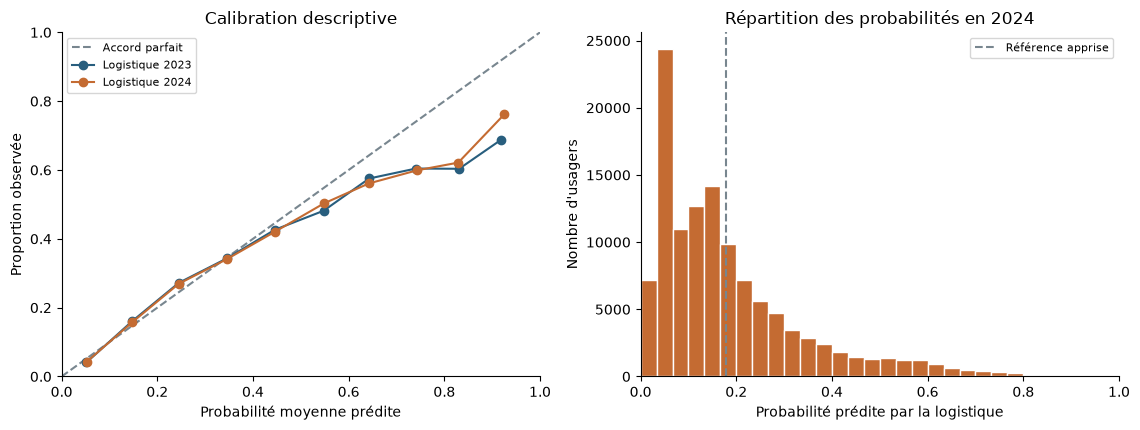

In [7]:
calibration_parts = []
for year, y, predictions, reference in [
    (VALIDATION_YEAR, y_validation, validation_predictions, validation_reference),
    (TEST_YEAR, y_test, test_predictions, test_reference),
]:
    for label, probabilities in [("Référence constante", reference), ("Régression logistique", predictions)]:
        frame = pd.DataFrame({"probabilite": probabilities, "cible": y})
        frame["intervalle"] = pd.cut(frame["probabilite"], bins=np.linspace(0, 1, 11), include_lowest=True)
        grouped = frame.groupby("intervalle", observed=True).agg(
            usagers=("cible", "size"), cas_positifs=("cible", "sum"),
            probabilite_moyenne=("probabilite", "mean"), proportion_observee=("cible", "mean"),
        ).reset_index()
        grouped["intervalle"] = grouped["intervalle"].astype(str)
        grouped.insert(0, "modele", label)
        grouped.insert(0, "annee", year)
        calibration_parts.append(grouped)
calibration_table = pd.concat(calibration_parts, ignore_index=True)
export_table(calibration_table, "07_calibration_validation_test.csv")
display(calibration_table.loc[calibration_table["annee"].eq(TEST_YEAR)])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot([0, 1], [0, 1], linestyle="--", color=GREY, label="Accord parfait")
for year, color in [(VALIDATION_YEAR, BLUE), (TEST_YEAR, ORANGE)]:
    points = calibration_table.loc[calibration_table["annee"].eq(year) & calibration_table["modele"].eq("Régression logistique")]
    axes[0].plot(points["probabilite_moyenne"], points["proportion_observee"], marker="o", color=color, label=f"Logistique {year}")
axes[0].set(xlabel="Probabilité moyenne prédite", ylabel="Proportion observée",
            title="Calibration descriptive", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=8)
axes[1].hist(test_predictions, bins=np.linspace(0, 1, 31), color=ORANGE, edgecolor="white")
axes[1].axvline(reference_probability, linestyle="--", color=GREY, label="Référence apprise")
axes[1].set(xlabel="Probabilité prédite par la logistique", ylabel="Nombre d'usagers",
            title="Répartition des probabilités en 2024", xlim=(0, 1))
axes[1].legend(fontsize=8)
fig.tight_layout()
export_figure(fig, "07_01_calibration_test.png")
plt.show()


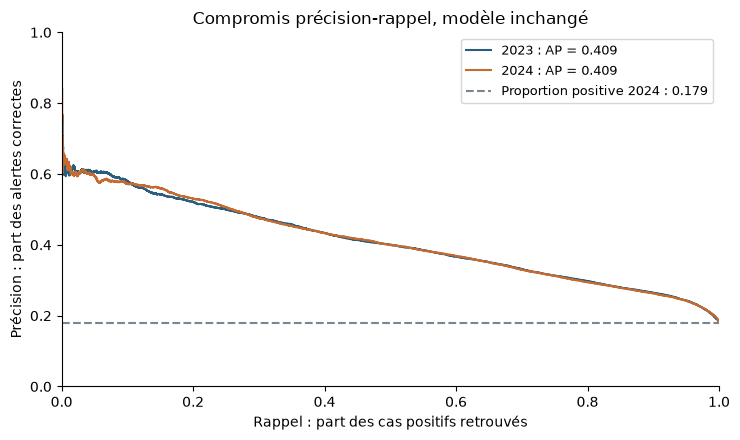

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for year, y, probabilities, color in [
    (VALIDATION_YEAR, y_validation, validation_predictions, BLUE),
    (TEST_YEAR, y_test, test_predictions, ORANGE),
]:
    precision, recall, _ = precision_recall_curve(y, probabilities)
    ap = average_precision_score(y, probabilities)
    ax.step(recall, precision, where="post", color=color, label=f"{year} : AP = {ap:.3f}")
ax.axhline(y_test.mean(), color=GREY, linestyle="--", label=f"Proportion positive 2024 : {y_test.mean():.3f}")
ax.set(xlabel="Rappel : part des cas positifs retrouvés", ylabel="Précision : part des alertes correctes",
       title="Compromis précision-rappel, modèle inchangé", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=9)
fig.tight_layout()
export_figure(fig, "07_02_precision_rappel_test.png")
plt.show()


Le profil de calibration reste proche de celui de 2023. La logistique surestime les
probabilités les plus élevées : dans l'intervalle 0,7-0,8, la moyenne prédite est de **74,28 %**
pour une fréquence observée de **59,94 %**, sur **1 031 usagers**. L'intervalle 0,8-0,9
comprend 214 usagers et celui au-dessus de 0,9 seulement 21 : ces dernières fréquences demandent
une prudence supplémentaire. Le gain de Brier n'autorise donc pas à parler de calibration parfaite.

Les courbes précision-rappel des deux années sont proches dans cette exécution. Cela décrit
la stabilité de ce compromis sur les deux populations observées, pas une garantie pour d'autres années.

La ligne horizontale de précision-rappel utilise la proportion positive observée en 2024
comme repère descriptif. Elle ne sert pas à modifier la référence constante, qui reste apprise
sur 2019-2022. L'AP est calculée selon la définition d'average precision, sans être renommée
aire trapézoïdale sous la courbe.

## 6. Décrire les erreurs au seuil annoncé

Le seuil illustratif reste 0,5. Nous ne le déplaçons pas après avoir vu les résultats du test.
Nous comptons les cas positifs retrouvés, ceux manqués et les fausses alertes. Lorsque le modèle
ne déclenche aucune alerte, la précision est indéfinie et reste manquante dans le tableau.
L'absence d'objectif opérationnel et de coût des erreurs interdit d'appeler ce seuil « optimal ».


In [9]:
threshold_rows = []
for year, y, predictions, reference in [
    (VALIDATION_YEAR, y_validation, validation_predictions, validation_reference),
    (TEST_YEAR, y_test, test_predictions, test_reference),
]:
    for label, probabilities in [("Référence constante", reference), ("Régression logistique", predictions)]:
        predicted = (probabilities >= THRESHOLD).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
        alerts = int(predicted.sum())
        threshold_rows.append({
            "annee": year, "modele": label, "seuil": THRESHOLD,
            "vrais_negatifs": int(tn), "fausses_alertes": int(fp), "cas_manques": int(fn),
            "vrais_positifs": int(tp), "alertes": alerts,
            "precision": float(tp / alerts) if alerts else np.nan,
            "rappel": float(tp / (tp + fn)), "accuracy": float((tp + tn) / len(y)),
        })
threshold_table = pd.DataFrame(threshold_rows)
export_table(threshold_table, "07_erreurs_seuil_050.csv")
display(threshold_table)


,annee,modele,seuil,vrais_negatifs,fausses_alertes,cas_manques,vrais_positifs,alertes,precision,rappel,accuracy
0,2023,Référence constante,0.5,96883,0,21218,0,0,NaN,0.000000,0.820340
1,2023,Régression logistique,0.5,93460,3423,17367,3851,7274,0.52942,0.181497,0.823964
2,2024,Référence constante,0.5,96254,0,21024,0,0,NaN,0.000000,0.820734
3,2024,Régression logistique,0.5,92962,3292,17194,3830,7122,0.53777,0.182173,0.825321


À 0,5, la logistique produit **7 122 alertes** : **3 830 correctes** et **3 292 fausses alertes**.
Elle manque **17 194 des 21 024 cas positifs**. La précision vaut **53,78 %** et le rappel
**18,22 %**, des résultats proches de ceux de la validation.

L'accuracy est de **82,53 %**, contre **82,07 %** pour la référence qui ne déclenche aucune
alerte. La lecture de cette seule métrique masquerait le faible rappel. La comparaison
probabiliste est favorable à la logistique ; la règle de décision illustrative reste peu
sensible aux cas positifs. Nous conservons le seuil annoncé, sans le qualifier de règle métier.

## 7. Lire les sous-populations et la qualité des informations

Les diagnostics portent sur les catégories d'usagers, les tranches d'âge déjà fixées et la
présence simultanée de l'âge et du sexe. Pour chaque groupe, le tableau donne le dénominateur,
la proportion observée, la probabilité moyenne et les scores de la logistique et de la référence.
Un accord des moyennes n'assure pas un bon classement des personnes à l'intérieur du groupe.

La restriction aux usagers dont l'âge et le sexe sont renseignés réutilise les mêmes prédictions.
Elle ne réentraîne pas le modèle et ne corrige pas les biais de collecte. Une seule classe dans
un groupe rend AP et ROC-AUC non renseignées dans notre diagnostic. Tous les écarts restent
descriptifs ; nous n'utilisons pas d'intervalle supposant les usagers d'un même accident indépendants.


In [10]:
unknown_rows, missing_rows = [], []
for year, frame, features in [(VALIDATION_YEAR, validation, X_validation), (TEST_YEAR, test, X_test)]:
    for variable, categories in zip(MODEL_FEATURES, encoder.categories_):
        unseen = ~features[variable].isin(categories)
        unknown_rows.append({"annee": year, "variable": variable,
                             "usagers_modalite_jamais_vue": int(unseen.sum()),
                             "proportion_pct": float(100 * unseen.mean()),
                             "modalites": json.dumps(sorted(features.loc[unseen, variable].unique().tolist()), ensure_ascii=False)})
    for variable in SOURCE_FEATURES:
        missing_rows.append({"annee": year, "variable": variable,
                             "manquants": int(frame[variable].isna().sum()),
                             "proportion_manquante_pct": float(100 * frame[variable].isna().mean())})
unknown_categories = pd.DataFrame(unknown_rows)
missingness = pd.DataFrame(missing_rows)
export_table(unknown_categories, "07_modalites_nouvelles.csv")
export_table(missingness, "07_valeurs_manquantes.csv")
display(unknown_categories.loc[unknown_categories["annee"].eq(TEST_YEAR)])
display(missingness.pivot(index="variable", columns="annee", values="proportion_manquante_pct").round(3))


,annee,variable,usagers_modalite_jamais_vue,proportion_pct,modalites
11,2024,tranche_age,0,0.0,[]
12,2024,sexe,0,0.0,[]
13,2024,catu,0,0.0,[]
14,2024,catv,0,0.0,[]
15,2024,lum,0,0.0,[]
16,2024,agg,0,0.0,[]
17,2024,int,0,0.0,[]
18,2024,atm,0,0.0,[]
19,2024,mois_accident,0,0.0,[]
20,2024,jour_semaine,0,0.0,[]


annee,2023,2024
variable,,
age_approx,1.990,2.063
agg,0.000,0.000
atm,0.004,0.000
catu,0.000,0.000
catv,0.247,0.281
heure_accident,0.000,0.000
int,0.008,0.000
jour_semaine,0.000,0.000
lum,0.001,0.000


,annee,dimension,groupe,usagers,cas_positifs,proportion_observee,probabilite_moyenne,log_loss,brier,average_precision,roc_auc,log_loss_reference,brier_reference
14,2024,catégorie,Conducteur,86838,14608,0.168221,0.170417,0.372549,0.116620,0.434851,0.792115,0.453378,0.140016
15,2024,catégorie,Passager,21526,3514,0.163244,0.167563,0.413216,0.128624,0.298504,0.697046,0.445759,0.136810
16,2024,catégorie,Piéton,8914,2902,0.325555,0.328112,0.636233,0.221238,0.414416,0.615425,0.694228,0.241379
17,2024,âge,0-17 ans,10681,2056,0.192491,0.197311,0.450829,0.143706,0.357079,0.699192,0.490531,0.155652
18,2024,âge,18-24 ans,21867,4019,0.183793,0.186142,0.430289,0.136794,0.357092,0.725104,0.477215,0.150048
19,2024,âge,25-34 ans,22528,3276,0.145419,0.148002,0.358997,0.110229,0.346858,0.761365,0.418472,0.125326
20,2024,âge,35-44 ans,18159,2577,0.141913,0.143616,0.344679,0.105157,0.374064,0.779537,0.413105,0.123067
21,2024,âge,45-54 ans,15602,2606,0.167030,0.165880,0.373925,0.116636,0.426891,0.786619,0.451554,0.139248
22,2024,âge,55-64 ans,12295,2452,0.199431,0.205004,0.423122,0.135358,0.443348,0.768108,0.501154,0.160123
23,2024,âge,65-74 ans,7140,1877,0.262885,0.266651,0.504162,0.168374,0.473076,0.740679,0.598291,0.201004


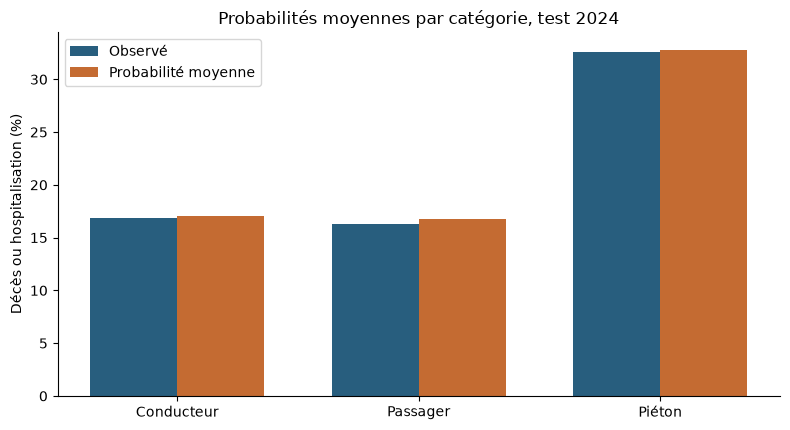

In [11]:
category_labels = {"1": "Conducteur", "2": "Passager", "3": "Piéton"}
segment_rows = []
for year, frame, features, y, probabilities, reference in [
    (VALIDATION_YEAR, validation, X_validation, y_validation, validation_predictions, validation_reference),
    (TEST_YEAR, test, X_test, y_test, test_predictions, test_reference),
]:
    specifications = [("catégorie", label, frame["catu"].eq(value).to_numpy(dtype=bool))
                      for value, label in category_labels.items()]
    specifications += [("âge", label, features["tranche_age"].eq(label).to_numpy(dtype=bool))
                       for label in [*AGE_LABELS, MISSING]]
    complete = frame[["age_approx", "sexe"]].notna().all(axis=1).to_numpy(dtype=bool)
    specifications += [("complétude", "Âge et sexe renseignés", complete),
                       ("complétude", "Âge ou sexe non renseigné", ~complete)]
    for dimension, label, mask in specifications:
        if not mask.any():
            continue
        y_segment, p_segment = y[mask], probabilities[mask]
        reference_scores = probability_metrics(y_segment, reference[mask])
        segment_rows.append({
            "annee": year, "dimension": dimension, "groupe": label,
            "usagers": int(mask.sum()), "cas_positifs": int(y_segment.sum()),
            "proportion_observee": float(y_segment.mean()), "probabilite_moyenne": float(p_segment.mean()),
            **probability_metrics(y_segment, p_segment),
            "log_loss_reference": reference_scores["log_loss"], "brier_reference": reference_scores["brier"],
        })
segments = pd.DataFrame(segment_rows)
export_table(segments, "07_diagnostics_sous_populations.csv")
display(segments.loc[segments["annee"].eq(TEST_YEAR)])

points = segments.loc[segments["annee"].eq(TEST_YEAR) & segments["dimension"].eq("catégorie")]
x = np.arange(len(points))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(x - 0.18, 100 * points["proportion_observee"], width=0.36, color=BLUE, label="Observé")
ax.bar(x + 0.18, 100 * points["probabilite_moyenne"], width=0.36, color=ORANGE, label="Probabilité moyenne")
ax.set_xticks(x, points["groupe"])
ax.set(ylabel="Décès ou hospitalisation (%)", title="Probabilités moyennes par catégorie, test 2024")
ax.legend()
fig.tight_layout()
export_figure(fig, "07_03_diagnostics_categories_test.png")
plt.show()


La ROC-AUC de 2024 vaut **0,792 chez les conducteurs**, **0,697 chez les passagers** et
**0,615 chez les piétons**. Le constat du notebook 06 se maintient : le classement est moins
informatif au sein du groupe des piétons. Pour ce groupe, la probabilité moyenne prédite est
de **32,81 %**, contre **32,56 %** observés. Cet accord moyen ne résout pas la difficulté de
classement individuel.

Sur les **114 854 usagers dont l'âge et le sexe sont renseignés**, la log-loss reste inférieure
à la référence : **0,4084 contre 0,4761**. Le gain n'est donc pas uniquement dû aux informations
absentes. Les **2 424 autres usagers ne comprennent qu'un seul cas positif**. Leur ROC-AUC,
bien que calculable, ne constitue pas une évaluation solide du classement avec un seul cas.
Il faut retenir ce dénominateur et la particularité de collecte, sans y voir une protection
associée à l'absence d'information.

Aucune modalité nouvelle n'est rencontrée en 2024 dans les onze variables représentées.
Les effectifs et les taux d'absence sont néanmoins conservés dans les exports pour rendre
la vérification possible avec d'autres versions des données.

## 8. Conserver une trace de l'évaluation

Nous enregistrons une copie de la configuration effectivement évaluée sous un nom préfixé 07,
ainsi que les résultats et les versions. La configuration du notebook 06 reste inchangée.
Ces exports ne contiennent pas de prédictions individuelles. Les tableaux agrégés permettent
de relire les résultats et de reconstruire les principaux dénominateurs.

Le modèle conserve les choix arrêtés sur la validation, même si un score de test est moins bon
ou si un groupe présente des limites. Réentraîner d'autres variantes après cette lecture serait
une nouvelle exploration et demanderait une autre stratégie pour leur évaluation indépendante.


In [12]:
assert file_sha256(CONFIG_PATH) == configuration_sha256
assert file_sha256(DATA_PATH) == configuration["sha256_donnees"]
assert file_sha256(SOURCE_DIR / "baac_ml.py") == configuration["sha256_module"]
assert all(np.array_equal(before, after) for before, after in zip(categories_before_test, encoder.categories_))
for year, y in [(VALIDATION_YEAR, y_validation), (TEST_YEAR, y_test)]:
    for dimension in ["catégorie", "âge", "complétude"]:
        group = segments.loc[segments["annee"].eq(year) & segments["dimension"].eq(dimension)]
        assert int(group["usagers"].sum()) == len(y)
        assert int(group["cas_positifs"].sum()) == int(y.sum())
    for label in ["Référence constante", "Régression logistique"]:
        group = calibration_table.loc[calibration_table["annee"].eq(year) & calibration_table["modele"].eq(label)]
        assert int(group["usagers"].sum()) == len(y)
        assert int(group["cas_positifs"].sum()) == int(y.sum())

metadata = {
    **test_protocol, "date_fin_utc": datetime.now(timezone.utc).isoformat(),
    "notebook": "07_final_evaluation.ipynb", "test_calcule": True,
    "usagers_test_connus": len(test), "usagers_test_inconnus": int(test_all[TARGET].isna().sum()),
    "scores_test_reference": reference_test_metrics, "scores_test_logistique": test_metrics,
    "modele_retenu_avant_test": selected_model_name, "modele_change_apres_test": False,
    "colonnes_apres_encodage": int(len(encoder.get_feature_names_out())),
    "maximum_ecart_reconstruction": float(reconstruction["ecart_absolu"].max()),
    "tables": tables_written, "figures": figures_written,
    "limites": ["test rétrospectif, 2024 déjà auditée", "cible sensible à la collecte",
                 "scores descriptifs sans correction des dépendances entre accidents",
                 "aucune utilité opérationnelle démontrée", "aucune conclusion causale"],
}
if EXPORT_RESULTS:
    assert len(tables_written) == 9 and len(figures_written) == 3
    for filename, content in [("07_configuration_evaluee.json", configuration),
                              ("07_metadonnees_test.json", metadata)]:
        (TABLE_DIR / filename).write_text(json.dumps(content, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(pd.Series({
    "modèle_conservé": selected_model_name, "C_logistique": configuration["C_retenu_logistique"],
    "usagers_test_à_gravité_connue": len(test), "cible_inconnue_test": int(test_all[TARGET].isna().sum()),
    "tableaux_CSV_exportés": len(tables_written), "graphiques_exportés": len(figures_written),
    "configuration_du_06_modifiée": False,
}, name="bilan"))


modèle_conservé                  regression_logistique
C_logistique                                       1.0
usagers_test_à_gravité_connue                   117278
cible_inconnue_test                                  0
tableaux_CSV_exportés                                9
graphiques_exportés                                  3
configuration_du_06_modifiée                     False
Name: bilan, dtype: object

## Conclusion de la modélisation

**La réponse est positive dans le périmètre étudié : le gain probabiliste constaté sur 2023
se maintient sur 2024, avec le modèle et les règles inchangés.** La logistique L2 avec C = 1,
apprise sur 2019-2022, améliore la log-loss de **14,93 %** et le Brier de **13,84 %** face à la
référence constante sur le test. Les scores de classement restent proches de la validation.

Cette stabilité ne suffit pas à défendre un outil opérationnel. Le seuil illustratif ne
retrouve que **18,22 %** des cas positifs, la calibration est imparfaite et le classement reste
limité parmi les piétons. Les valeurs manquantes portent un signal particulier de collecte.
Nous rapportons ces limites avec les gains, sans modifier les choix après consultation du test.

Le projet a maintenant parcouru les sources, l'audit, la préparation, l'exploration, les
comparaisons statistiques puis une étude prédictive limitée et évaluée dans le temps.
Le modèle a été confronté à une référence constante, les absences sont explicites et
les différences entre populations ont été examinées.

Cette étude ne démontre pas une utilité opérationnelle. Elle décrit ce que des caractéristiques
de dossiers d'accidents enregistrés permettent d'estimer, sous une cible et une représentation
précises. La sous-déclaration, la collecte de l'hospitalisation, les informations absentes,
l'âge regroupé et l'absence d'interactions explicites limitent l'interprétation.
Les associations ne sont pas des effets causaux et les résultats ne mesurent pas un risque par trajet.

Les limites du test restent à rapporter avec les scores, même lorsque ceux-ci sont favorables.
La suite du travail porte sur la restitution : compléter la partie ML du rapport et la conclusion
générale, puis harmoniser le README et le cahier des charges avec les livrables réellement produits.

### Références techniques

- [scikit-learn : LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [scikit-learn : mesures d'évaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn : calibration des probabilités](https://scikit-learn.org/stable/modules/calibration.html)
- [scikit-learn : séparation entre apprentissage et test](https://scikit-learn.org/stable/common_pitfalls.html)

La population, les règles de préparation et la sélection proviennent des notebooks 01 à 06
et de la configuration enregistrée avant l'évaluation de 2024.
